# AI651 – Deep Learning for Space, Time and Graphs
# Assignment 3

Syed Obaidullah Hassan Chishti - 25280049

## Question 4 - Spatio-Temporal Traffic Forecasting

# Imports

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

seed = 2023
torch.manual_seed(seed)
np.random.seed(seed)

Device: cuda


# Question 4 - Spatio-Temporal Traffic Forecasting

## Check and download the dataset

In [2]:
import kagglehub

DATA_DIR = kagglehub.dataset_download("liuxu77/largest")
print("Dataset directory:", DATA_DIR)
print("Files:", sorted(os.listdir(DATA_DIR)))

# Sanity check that the files we need are present
for f in ["ca_meta.csv", "ca_rn_adj.npy", "ca_his_raw_2020.h5", "ca_his_raw_2021.h5"]:
    path = os.path.join(DATA_DIR, f)
    print(("OK  " if os.path.exists(path) else "MISSING "), f)

/home/obaid/miniconda3/envs/dl4stg_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset directory: /home/obaid/.cache/kagglehub/datasets/liuxu77/largest/versions/1
Files: ['ca_his_raw_2017.h5', 'ca_his_raw_2018.h5', 'ca_his_raw_2019.h5', 'ca_his_raw_2020.h5', 'ca_his_raw_2021.h5', 'ca_meta.csv', 'ca_rn_adj.npy']
OK   ca_meta.csv
OK   ca_rn_adj.npy
OK   ca_his_raw_2020.h5
OK   ca_his_raw_2021.h5


## Load the San Diego data

In [3]:
# Metadata -> San Diego (District 11) sensors
ca_meta = pd.read_csv(os.path.join(DATA_DIR, "ca_meta.csv"))
sd_meta = ca_meta[ca_meta.District == 11].reset_index(drop=True)
sd_ids = sd_meta.ID.astype(str).values.tolist()      # flow column names
sd_pos = sd_meta.ID2.values.tolist()                 # adjacency indices
N = len(sd_meta)
print("SD sensors:", N)

# Flow for 2020 and 2021, 15-minute averages, missing values filled
frames = [pd.read_hdf(os.path.join(DATA_DIR, f"ca_his_raw_{y}.h5"))[sd_ids] for y in ["2020", "2021"]]
flow = pd.concat(frames).sort_index()
flow.index = pd.to_datetime(flow.index)
flow = flow.resample("15min").mean()
# interpolate gaps, fill edges, then zero-out any fully-empty sensors (no NaNs left)
flow = flow.interpolate(method="time", limit_direction="both").ffill().bfill().fillna(0.0)
print("Flow tensor:", flow.shape)

# Aligned adjacency (same order as the flow columns)
ca_rn_adj = np.load(os.path.join(DATA_DIR, "ca_rn_adj.npy"))
A_sd = ca_rn_adj[np.ix_(sd_pos, sd_pos)]
print("Adjacency:", A_sd.shape)

SD sensors: 716


Flow tensor: (70176, 716)
Adjacency: (716, 716)


### Normalized adjacency

In [4]:
def normalize_adj(A):
    A = A + np.eye(A.shape[0])          # add self-loops
    deg = A.sum(axis=1)
    d_inv_sqrt = np.power(deg, -0.5, out=np.zeros_like(deg), where=deg > 0)
    D = np.diag(d_inv_sqrt)
    return D @ A @ D

A_hat = torch.tensor(normalize_adj(A_sd), dtype=torch.float32, device=device)
print("A_hat:", tuple(A_hat.shape))

A_hat: (716, 716)


## Q4(a) - Preparing Forecasting Windows

In [5]:
T_in, T_out = 8, 4

# Split the time index chronologically
values = flow.values.astype(np.float32)          # (T, N)
idx = flow.index

train_mask = (idx >= "2020-01-01") & (idx < "2021-01-01")
val_mask   = (idx >= "2021-01-01") & (idx < "2021-04-01")
test_mask  = (idx >= "2021-04-01") & (idx < "2022-01-01")

train_vals = values[train_mask]
val_vals   = values[val_mask]
test_vals  = values[test_mask]
print("Split sizes (timestamps):", len(train_vals), len(val_vals), len(test_vals))

# Normalize with training statistics only
mean = train_vals.mean()
std  = train_vals.std()
print(f"Train mean={mean:.3f}, std={std:.3f}")

Split sizes (timestamps): 35136 8640 26400
Train mean=194.848, std=162.686


In [6]:
def make_windows(arr, mean, std):
    """arr: (T, N). Returns X (num, T_in, N, 1), Y (num, T_out, N, 1), normalized."""
    arr = (arr - mean) / std
    X, Y = [], []
    last = len(arr) - T_in - T_out + 1
    for t in range(last):
        X.append(arr[t : t + T_in])
        Y.append(arr[t + T_in : t + T_in + T_out])
    X = np.array(X)[..., None]     # (num, T_in, N, 1)
    Y = np.array(Y)[..., None]     # (num, T_out, N, 1)
    return torch.tensor(X), torch.tensor(Y)

Xtr, Ytr = make_windows(train_vals, mean, std)
Xva, Yva = make_windows(val_vals, mean, std)
Xte, Yte = make_windows(test_vals, mean, std)
print("Train windows:", tuple(Xtr.shape), "->", tuple(Ytr.shape))
print("Val windows:  ", tuple(Xva.shape))
print("Test windows: ", tuple(Xte.shape))

Train windows: (35125, 8, 716, 1) -> (35125, 4, 716, 1)
Val windows:   (8629, 8, 716, 1)
Test windows:  (26389, 8, 716, 1)


## Q4(b) - Forecasting Architecture

In [7]:
class TemporalEncoder(nn.Module):
    """Temporal convolution over each sensor's 8-step history."""
    def __init__(self, in_feats=1, hidden=32, k=3):
        super().__init__()
        self.conv1 = nn.Conv1d(in_feats, hidden, kernel_size=k, padding=k // 2)
        self.conv2 = nn.Conv1d(hidden, hidden, kernel_size=k, padding=k // 2)
        self.relu = nn.ReLU()

    def forward(self, x):
        # x: (B, T_in, N, F) -> (B*N, F, T_in)
        B, T, N, F = x.shape
        x = x.permute(0, 2, 3, 1).reshape(B * N, F, T)
        z = self.relu(self.conv1(x))
        z = self.relu(self.conv2(z))
        z = z.mean(dim=-1)                 # pool over time
        return z.reshape(B, N, -1)         # (B, N, hidden)


class STGNN(nn.Module):
    def __init__(self, hidden=32, horizon=T_out, use_graph=True):
        super().__init__()
        self.use_graph = use_graph
        self.temporal = TemporalEncoder(hidden=hidden)
        self.Wg = nn.Linear(hidden, hidden, bias=False)      # graph weights W_g
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, horizon))
        self.relu = nn.ReLU()

    def forward(self, x, A_hat=None):
        z = self.temporal(x)                                 # (B, N, hidden)
        if self.use_graph:
            # H = ReLU(A_hat Z W_g), graph mixing across the node dimension
            h = torch.einsum("nm,bmd->bnd", A_hat, z)
            h = self.relu(self.Wg(h))
        else:
            h = z                                            # temporal-only (Q4c)
        y = self.head(h)                                     # (B, N, horizon)
        return y.permute(0, 2, 1).unsqueeze(-1)              # (B, horizon, N, 1)

print("Model parameters (with graph):",
      sum(p.numel() for p in STGNN().parameters()))

Model parameters (with graph): 5444


### Training and evaluation helpers

In [8]:
def iterate(X, Y, bs, shuffle):
    n = len(X)
    order = torch.randperm(n) if shuffle else torch.arange(n)
    for s in range(0, n, bs):
        b = order[s : s + bs]
        yield X[b].to(device), Y[b].to(device)


def train_model(model, epochs=10, bs=64, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()
    history = []

    for epoch in range(epochs):
        model.train()
        t0 = time.perf_counter()
        total = 0.0
        for xb, yb in iterate(Xtr, Ytr, bs, shuffle=True):
            opt.zero_grad()
            pred = model(xb, A_hat)
            loss = loss_fn(pred, yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        history.append(total / len(Xtr))
        print(f"epoch {epoch+1:02d}  train MAE(norm) {history[-1]:.4f}  "
              f"({time.perf_counter()-t0:.1f}s)")
    return history


@torch.no_grad()
def evaluate(model, X, Y, bs=64):
    model.eval()
    preds, trues = [], []
    for xb, yb in iterate(X, Y, bs, shuffle=False):
        preds.append(model(xb, A_hat).cpu())
        trues.append(yb.cpu())
    pred = torch.cat(preds) * std + mean      # back to original units
    true = torch.cat(trues) * std + mean
    mae = (pred - true).abs().mean().item()
    rmse = ((pred - true) ** 2).mean().sqrt().item()
    return mae, rmse

### Train the spatio-temporal model (fixed road-distance adjacency)

In [9]:
stgnn = STGNN(hidden=32, use_graph=True)

t0 = time.perf_counter()
train_model(stgnn, epochs=10, bs=64)
stgnn_time = time.perf_counter() - t0

stgnn_val = evaluate(stgnn, Xva, Yva)
stgnn_test = evaluate(stgnn, Xte, Yte)
print(f"\nSTGNN  val  MAE {stgnn_val[0]:.3f}  RMSE {stgnn_val[1]:.3f}")
print(f"STGNN  test MAE {stgnn_test[0]:.3f}  RMSE {stgnn_test[1]:.3f}")
print(f"Training time: {stgnn_time:.1f}s")

epoch 01  train MAE(norm) 0.3439  (14.6s)
epoch 02  train MAE(norm) 0.2894  (8.0s)
epoch 03  train MAE(norm) 0.2796  (8.0s)
epoch 04  train MAE(norm) 0.2695  (8.5s)
epoch 05  train MAE(norm) 0.2639  (8.0s)
epoch 06  train MAE(norm) 0.2597  (8.1s)
epoch 07  train MAE(norm) 0.2567  (7.7s)
epoch 08  train MAE(norm) 0.2537  (8.2s)
epoch 09  train MAE(norm) 0.2509  (8.5s)
epoch 10  train MAE(norm) 0.2492  (9.1s)

STGNN  val  MAE 42.612  RMSE 72.098
STGNN  test MAE 47.817  RMSE 78.982
Training time: 95.3s


## Q4(c) - Temporal-Only Baseline

In [10]:
temporal_only = STGNN(hidden=32, use_graph=False)

t0 = time.perf_counter()
train_model(temporal_only, epochs=10, bs=64)
temporal_time = time.perf_counter() - t0

temp_val = evaluate(temporal_only, Xva, Yva)
temp_test = evaluate(temporal_only, Xte, Yte)
print(f"\nTemporal-only  val  MAE {temp_val[0]:.3f}  RMSE {temp_val[1]:.3f}")
print(f"Temporal-only  test MAE {temp_test[0]:.3f}  RMSE {temp_test[1]:.3f}")
print(f"Training time: {temporal_time:.1f}s")

epoch 01  train MAE(norm) 0.2117  (8.8s)
epoch 02  train MAE(norm) 0.1288  (6.8s)
epoch 03  train MAE(norm) 0.1244  (6.8s)
epoch 04  train MAE(norm) 0.1217  (6.9s)
epoch 05  train MAE(norm) 0.1203  (6.7s)
epoch 06  train MAE(norm) 0.1195  (7.1s)
epoch 07  train MAE(norm) 0.1187  (7.1s)
epoch 08  train MAE(norm) 0.1185  (6.8s)
epoch 09  train MAE(norm) 0.1178  (7.2s)
epoch 10  train MAE(norm) 0.1174  (7.6s)

Temporal-only  val  MAE 20.518  RMSE 33.510
Temporal-only  test MAE 23.561  RMSE 37.584
Training time: 71.7s


### Results table

In [11]:
results = pd.DataFrame([
    {"Model": "Temporal-only", "Adjacency": "None",
     "MAE": temp_test[0], "RMSE": temp_test[1], "Training time (s)": temporal_time},
    {"Model": "STGNN", "Adjacency": "Fixed",
     "MAE": stgnn_test[0], "RMSE": stgnn_test[1], "Training time (s)": stgnn_time},
])
print(results.to_string(index=False))

        Model Adjacency       MAE      RMSE  Training time (s)
Temporal-only      None 23.560778 37.584385          71.720131
        STGNN     Fixed 47.817116 78.982452          95.319023


### Predicted vs actual traffic flow (3 sensors)

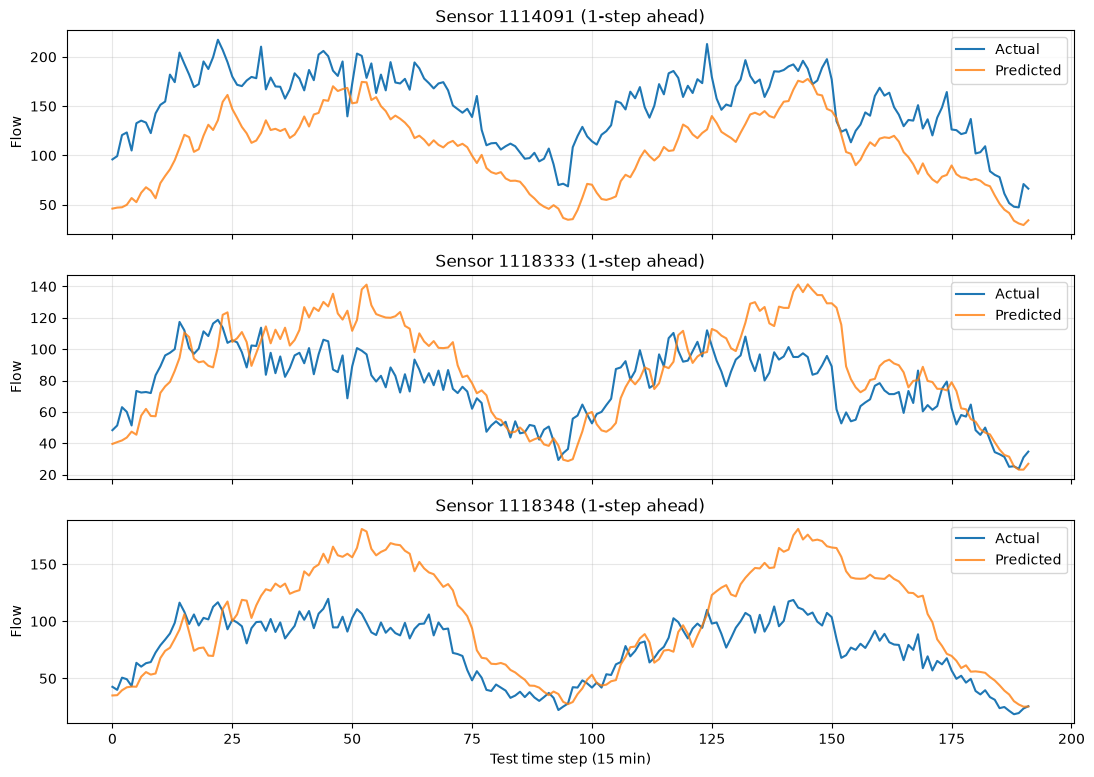

In [12]:
@torch.no_grad()
def collect_predictions(model):
    model.eval()
    preds = []
    for xb, _ in iterate(Xte, Yte, 64, shuffle=False):
        preds.append(model(xb, A_hat).cpu())
    pred = torch.cat(preds) * std + mean       # (num, T_out, N, 1)
    true = Yte * std + mean
    return pred, true

pred, true = collect_predictions(stgnn)

sensors = [0, 1, 2]
window = slice(0, 96 * 2)   # first two days of the test set (15-min steps)

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, s in zip(axes, sensors):
    ax.plot(true[window, 0, s, 0], label="Actual")
    ax.plot(pred[window, 0, s, 0], label="Predicted", alpha=0.8)
    ax.set(title=f"Sensor {sd_ids[s]} (1-step ahead)", ylabel="Flow")
    ax.legend(); ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Test time step (15 min)")

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/q4_pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()